In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from seaborn import heatmap
import seaborn as sns

In [2]:
from sklearn.datasets import load_wine

wine = load_wine()

X = wine.data
y = wine.target

df = pd.DataFrame(wine.data, columns=wine.feature_names)

df = df[['alcohol', 'malic_acid', 'proline', 'flavanoids', 'color_intensity']]
X = np.array(df)
y = wine.target
df.head()

,alcohol,malic_acid,proline,flavanoids,color_intensity
0,14.23,1.71,1065.0,3.06,5.64
1,13.20,1.78,1050.0,2.76,4.38
2,13.16,2.36,1185.0,3.24,5.68
3,14.37,1.95,1480.0,3.49,7.80
4,13.24,2.59,735.0,2.69,4.32


In [3]:


print("\nShapes:")
print("X:", X.shape)
print("y:", y.shape)

print(df.shape)
print(df.info())



Shapes:
X: (178, 5)
y: (178,)
(178, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   alcohol          178 non-null    float64
 1   malic_acid       178 non-null    float64
 2   proline          178 non-null    float64
 3   flavanoids       178 non-null    float64
 4   color_intensity  178 non-null    float64
dtypes: float64(5)
memory usage: 7.1 KB
None


In [4]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, train_size=0.7, random_state=42, shuffle=True)
X_valid, X_test, y_valid, y_test = train_test_split(X_tmp, y_tmp, test_size= 0.5, random_state=42, shuffle=True)


# Decision Tree: Splitting Criteria

A Decision Tree builds a classification model by repeatedly splitting the dataset into smaller subsets.

At each node, the algorithm tries to find the feature and splitting condition that produce the **purest possible child nodes**.

A node is pure when all its samples belong to the same class.

To evaluate the quality of a split, we use three important concepts:

1. Gini Impurity
2. Entropy
3. Information Gain

---

## 1. Gini Impurity

### Intuition

Gini Impurity measures the probability of incorrectly classifying a randomly selected sample if its class label is assigned randomly according to the class distribution of the node.

In simpler terms, it measures how mixed the classes are within a node.

- Gini = 0: The node is completely pure.
- Higher Gini: The node contains a greater mixture of different classes.

### Formula

For a node containing $K$ different classes:

$$
Gini = 1 - \sum_{i=1}^{K} p_i^2
$$

Where:

- $K$ is the number of distinct classes.
- $p_i$ is the proportion of samples belonging to class $i$.

### Example

Suppose a node contains 10 samples:

| Class | Samples | Probability |
|---|---:|---:|
| Normal Weight | 6 | 0.6 |
| Obesity Type I | 4 | 0.4 |

Then:

$$
Gini = 1 - (0.6^2 + 0.4^2)
$$

$$
Gini = 1 - (0.36 + 0.16)
$$

$$
\boxed{Gini = 0.48}
$$

If all 10 samples belonged to one class:

$$
Gini = 1 - 1^2 = 0
$$

Therefore, a lower Gini Impurity indicates a purer node.

---

## 2. Entropy

### Intuition

Entropy measures the uncertainty or disorder associated with the class distribution of a node.

Think of it as answering this question:

**How uncertain are we about the class of a randomly selected sample from this node?**

- Entropy = 0: There is no uncertainty; all samples belong to one class.
- Higher Entropy: There is more uncertainty about the class.

Entropy is based on information theory and measures uncertainty in bits.

### Formula

$$
H(S) = -\sum_{i=1}^{K} p_i \log_2(p_i)
$$

Where:

- $S$ represents the samples in the node.
- $K$ is the number of classes.
- $p_i$ is the proportion of samples belonging to class $i$.
- $\log_2$ is the logarithm with base 2.

By convention, $0\log_2(0)=0$.

### Example

Using the same node:

| Class | Probability |
|---|---:|
| Normal Weight | 0.6 |
| Obesity Type I | 0.4 |

$$
H(S) = -(0.6\log_2 0.6 + 0.4\log_2 0.4)
$$

$$
\boxed{H(S) \approx 0.971}
$$

If all samples belong to one class:

$$
H(S) = -1\log_2(1) = 0
$$

Therefore, lower entropy means less uncertainty and a purer node.

---

## 3. Information Gain

### Intuition

Information Gain measures how much uncertainty is reduced after splitting a node into child nodes.

In other words:

**How much better do we understand the class distribution after performing this split?**

A good split separates different classes into different child nodes, reducing their impurity.

The algorithm evaluates possible splits and prefers the one that produces the greatest reduction in impurity.

### Formula

Using entropy, Information Gain is calculated as:

$$
IG = H(S) - H_{\text{after split}}
$$

The entropy after splitting is the weighted average entropy of the child nodes:

$$
H_{\text{after split}} =
\sum_{j=1}^{m}
\frac{|S_j|}{|S|} H(S_j)
$$

Therefore:

$$
\boxed{
IG =
H(S) -
\sum_{j=1}^{m}
\frac{|S_j|}{|S|}H(S_j)
}
$$

Where:

- $S$ is the original parent node.
- $S_j$ is the $j$-th child node.
- $m$ is the number of child nodes.
- $|S_j|/|S|$ is the proportion of samples assigned to child $j$.

### Example

Suppose we have 10 samples in a parent node:

- 6 Normal Weight
- 4 Obesity Type I

The parent entropy is:

$$
H(S) \approx 0.971
$$

Now consider a split that produces two child nodes:

**Left child:**

- 5 Normal Weight
- 0 Obesity Type I

**Right child:**

- 1 Normal Weight
- 4 Obesity Type I

The left child is completely pure:

$$
H(S_1)=0
$$

The right child has:

$$
H(S_2) =
-\left(
\frac{1}{5}\log_2\frac{1}{5}
+
\frac{4}{5}\log_2\frac{4}{5}
\right)
$$

$$
H(S_2)\approx 0.722
$$

The weighted entropy after the split is:

$$
H_{\text{after split}} =
\frac{5}{10}(0)+
\frac{5}{10}(0.722)
$$

$$
H_{\text{after split}} \approx 0.361
$$

Finally:

$$
IG = 0.971 - 0.361
$$

$$
\boxed{IG \approx 0.610}
$$

This means the split reduced the uncertainty by approximately 0.610 bits.

A higher Information Gain indicates a better split.

---

## 4. Gini vs. Entropy vs. Information Gain

| Metric | What does it measure? | Preferred value |
|---|---|---|
| Gini Impurity | Class mixture in a node | Lower |
| Entropy | Uncertainty in a node | Lower |
| Information Gain | Reduction in entropy after a split | Higher |

### How are they related?

Gini Impurity and Entropy both measure the impurity of a node, but they use different mathematical approaches.

Information Gain measures the reduction in entropy resulting from a split.

Decision Trees can use either Gini Impurity or Entropy to evaluate candidate splits.

For example, in Scikit-learn:

- `criterion='gini'` uses Gini Impurity.
- `criterion='entropy'` uses Information Gain based on entropy.
- `criterion='log_loss'` uses Shannon information gain as well.

**Important:** Gini Impurity and Entropy do not have to produce exactly the same optimal split, although they often produce similar trees.

The ultimate objective is the same: find splits that create increasingly pure child nodes.


In [5]:
import numpy as np

class Node:
    def __init__(self, feature_idx=None, threshold=None, left=None, right=None, value=None):
        self.feature_idx = feature_idx
        self.threshold = threshold  
        self.left = left
        self.right = right
        self.value = value  

    @property
    def is_leaf(self):
        return self.value is not None


class DecisionTree:

    def __init__(self, criterion="gini", max_depth=None, min_samples_split=2):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split

        self.tree = None       
        self.n_classes = None
        self.classes = None
        self.n_features_in = None

    def split_data(self, X, y, feature_idx, condition):
        mask = np.asarray(condition(X[:, feature_idx]))

        if mask.dtype != bool:
            raise ValueError("Condition must return a Boolean array.")

        if mask.shape != (len(X),):
            raise ValueError("Condition must return one Boolean per sample.")

        if len(X) != len(y):
            raise ValueError("X and y must contain the same number of samples.")

        X_left, X_right = X[~mask], X[mask]
        y_left, y_right = y[~mask], y[mask]

        return X_left, X_right, y_left, y_right

    def probs(self, y, y_left, y_right):
        if len(y) == 0 or len(y_left) == 0 or len(y_right) == 0:
            raise ValueError("All nodes must contain samples.")

        if self.classes is None:
            self.classes = np.unique(y)
            self.n_classes = len(self.classes)
            
        root_counts = np.array([np.sum(y == c) for c in self.classes])
        left_counts = np.array([np.sum(y_left == c) for c in self.classes])
        right_counts = np.array([np.sum(y_right == c) for c in self.classes])

        probs_root = root_counts / len(y)
        probs_left = left_counts / len(y_left)
        probs_right = right_counts / len(y_right)

        sizes = (len(y), len(y_left), len(y_right))

        return probs_root, probs_left, probs_right, sizes

    def gini_impurity(self, probs):
        return 1 - np.sum(np.square(probs))

    def entropy(self, probs):
        probs = np.asarray(probs)
        probs = probs[probs > 0]
        return -np.sum(probs * np.log2(probs))

    def inf_gain(self, probs_root, probs_left, probs_right, root_size, left_size, right_size):
        if self.criterion == "gini":
            root_score = self.gini_impurity(probs_root)
            left_score = self.gini_impurity(probs_left)
            right_score = self.gini_impurity(probs_right)
        elif self.criterion == "entropy":
            root_score = self.entropy(probs_root)
            left_score = self.entropy(probs_left)
            right_score = self.entropy(probs_right)
        else:
            raise ValueError("criterion not found")

        after_split_score = (
            (left_size / root_size) * left_score
            + (right_size / root_size) * right_score
        )

        return root_score - after_split_score
    
    def best_split(self, X, y):
        best_gain, best_feat, best_thresh = -1.0, None, None

        for fidx in range(self.n_features_in):
            thresholds = np.unique(X[:, fidx])
            if len(thresholds) <= 1:
                continue

            for t in thresholds:
                condition = lambda col, val=t: col >= val

                try:
                    X_l, X_r, y_l, y_r = self.split_data(X, y, fidx, condition)
                    if len(y_l) == 0 or len(y_r) == 0:
                        continue
                except ValueError:
                    continue

                p_root, p_left, p_right, sizes = self.probs(y, y_l, y_r)
                ig = self.inf_gain(p_root, p_left, p_right, *sizes)

                if ig > best_gain:
                    best_gain, best_feat, best_thresh = ig, fidx, t

        return best_gain, best_feat, best_thresh
    
    def build_tree(self, X, y, depth=0):
        n_samples = len(y)
        
        if (self.max_depth is not None and depth >= self.max_depth) or \
           n_samples < self.min_samples_split or \
           np.all(y == y[0]):
            
            leaf_value = np.bincount(y).argmax()
            return Node(value=leaf_value)
        
        best_gain, best_feat, best_thresh = self.best_split(X, y)

        if best_feat is None or best_gain <= 0.0:
            leaf_value = np.bincount(y).argmax()
            return Node(value=leaf_value)
        
        condition = lambda col, val=best_thresh: col >= val
        X_left, X_right, y_left, y_right = self.split_data(X, y, best_feat, condition)
        
        left_child = self.build_tree(X_left, y_left, depth + 1)
        right_child = self.build_tree(X_right, y_right, depth + 1)
        
        return Node(feature_idx=best_feat, threshold=best_thresh, left=left_child, right=right_child)
            
    def fit(self, X, y):
        self.n_features_in = X.shape[1]
        self.classes = np.unique(y)
        self.n_classes = len(self.classes)
        
        self.tree = self.build_tree(X, y, depth=0)
        return self
   
    def _predict_row(self, node, x):
        if node.is_leaf:
            return node.value
        
        if x[node.feature_idx] >= node.threshold:
            return self._predict_row(node.right, x)
        return self._predict_row(node.left, x)

    def predict(self, X):
        return np.array([self._predict_row(self.tree, x) for x in X])
    
    

Validation Accuracy: 96.30%


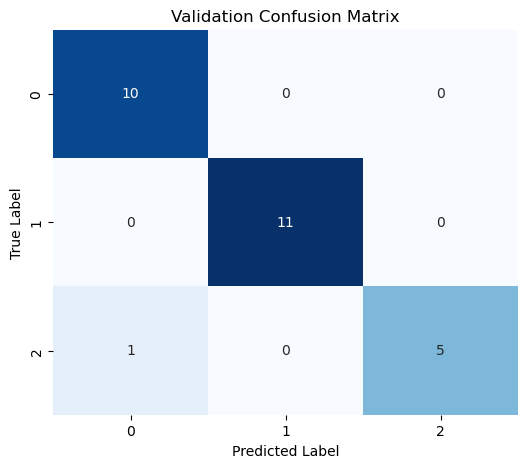

In [6]:
model = DecisionTree(max_depth=5, criterion="gini")
model.fit(X_train, y_train)
y_pred = model.predict(X_valid)
cm = confusion_matrix(y_valid, y_pred)

accuracy = accuracy_score(y_valid, y_pred)
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=model.classes, yticklabels=model.classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Validation Confusion Matrix")
plt.show()

test Accuracy: 100.00%


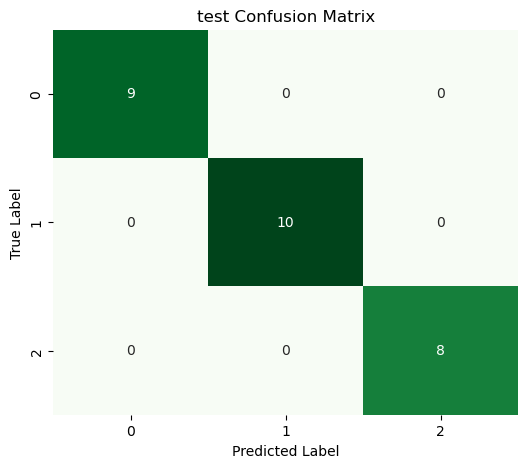

In [7]:

y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

accuracy = accuracy_score(y_test, y_pred)
print(f"test Accuracy: {accuracy * 100:.2f}%")

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=model.classes, yticklabels=model.classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("test Confusion Matrix")
plt.show()

<img src="wine_tree.png" alt="Decision Tree" height = "800" width="1300" style="display: block; margin: 0 auto;">

In [1]:
!jupyter nbconvert --to pdf "Decision_Tree_from_scratch.ipynb"

[NbConvertApp] Converting notebook Decision_Tree_from_scratch.ipynb to pdf
[NbConvertApp] Support files will be in Decision_Tree_from_scratch_files\
[NbConvertApp] Making directory .\Decision_Tree_from_scratch_files
[NbConvertApp] Writing 56181 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | b had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 92499 bytes to Decision_Tree_from_scratch.pdf
